In [1]:

import pandas as pd

archivo = "Reto M2S5.xlsx"

df = pd.read_excel(
    archivo,
    sheet_name="Primer Reto",
    usecols="A:B",
    skiprows=2
)

df.head(10)


,name,weight_kg
0,Bulbasaur,6.9
1,Ivysaur,13.0
2,Venusaur,100.0
3,Charmander,8.5
4,Charmeleon,19.0
5,Charizard,90.5
6,Squirtle,9.0
7,Wartortle,22.5
8,Blastoise,85.5
9,Caterpie,2.9


In [2]:

peso_maximo = df["weight_kg"].max()
peso_minimo = df["weight_kg"].min()
rango = peso_maximo - peso_minimo
numero_datos = df["weight_kg"].count()

print("Peso máximo:", peso_maximo, "kg")
print("Peso mínimo:", peso_minimo, "kg")
print("Rango:", rango, "kg")
print("Número de datos:", numero_datos)


Peso máximo: 999.9 kg
Peso mínimo: 0.1 kg
Rango: 999.8 kg
Número de datos: 781


In [3]:

import math

numero_categorias = math.ceil(
    1 + 3.322 * math.log10(numero_datos)
)

print("Número de categorías:", numero_categorias)


Número de categorías: 11


In [4]:

amplitud = math.ceil(rango / numero_categorias)

print("Amplitud de los intervalos:", amplitud, "kg")


Amplitud de los intervalos: 91 kg


In [5]:

import numpy as np

limites = [
    peso_minimo + i * amplitud
    for i in range(numero_categorias + 1)
]

intervalos = pd.cut(
    df["weight_kg"],
    bins=limites,
    include_lowest=True
)

print("Intervalos de peso:")
print(intervalos.cat.categories)


Intervalos de peso:
IntervalIndex([  (0.099, 91.1],   (91.1, 182.1],  (182.1, 273.1],
                (273.1, 364.1],  (364.1, 455.1],  (455.1, 546.1],
                (546.1, 637.1],  (637.1, 728.1],  (728.1, 819.1],
                (819.1, 910.1], (910.1, 1001.1]],
              dtype='interval[float64, right]')


In [6]:

frecuencia_absoluta = intervalos.value_counts().sort_index()

tabla_frecuencias = pd.DataFrame({
    "Intervalo de peso (kg)": frecuencia_absoluta.index.astype(str),
    "Frecuencia absoluta (fi)": frecuencia_absoluta.values
})

tabla_frecuencias


,Intervalo de peso (kg),Frecuencia absoluta (fi)
0,"(0.099, 91.1]",646
1,"(91.1, 182.1]",70
2,"(182.1, 273.1]",36
3,"(273.1, 364.1]",15
4,"(364.1, 455.1]",4
5,"(455.1, 546.1]",2
6,"(546.1, 637.1]",1
7,"(637.1, 728.1]",1
8,"(728.1, 819.1]",1
9,"(819.1, 910.1]",1


In [7]:

tabla_frecuencias["Frecuencia relativa (hi)"] = (
    tabla_frecuencias["Frecuencia absoluta (fi)"] / numero_datos
)

tabla_frecuencias["Frecuencia acumulada (Fi)"] = (
    tabla_frecuencias["Frecuencia absoluta (fi)"].cumsum()
)

tabla_frecuencias


,Intervalo de peso (kg),Frecuencia absoluta (fi),Frecuencia relativa (hi),Frecuencia acumulada (Fi)
0,"(0.099, 91.1]",646,0.827145,646
1,"(91.1, 182.1]",70,0.089629,716
2,"(182.1, 273.1]",36,0.046095,752
3,"(273.1, 364.1]",15,0.019206,767
4,"(364.1, 455.1]",4,0.005122,771
5,"(455.1, 546.1]",2,0.002561,773
6,"(546.1, 637.1]",1,0.001280,774
7,"(637.1, 728.1]",1,0.001280,775
8,"(728.1, 819.1]",1,0.001280,776
9,"(819.1, 910.1]",1,0.001280,777


In [8]:

tabla_frecuencias["Porcentaje (%)"] = (
    tabla_frecuencias["Frecuencia relativa (hi)"] * 100
).round(2)

tabla_frecuencias


,Intervalo de peso (kg),Frecuencia absoluta (fi),Frecuencia relativa (hi),Frecuencia acumulada (Fi),Porcentaje (%)
0,"(0.099, 91.1]",646,0.827145,646,82.71
1,"(91.1, 182.1]",70,0.089629,716,8.96
2,"(182.1, 273.1]",36,0.046095,752,4.61
3,"(273.1, 364.1]",15,0.019206,767,1.92
4,"(364.1, 455.1]",4,0.005122,771,0.51
5,"(455.1, 546.1]",2,0.002561,773,0.26
6,"(546.1, 637.1]",1,0.001280,774,0.13
7,"(637.1, 728.1]",1,0.001280,775,0.13
8,"(728.1, 819.1]",1,0.001280,776,0.13
9,"(819.1, 910.1]",1,0.001280,777,0.13


In [9]:

print("Total de Pokémon:", tabla_frecuencias["Frecuencia absoluta (fi)"].sum())

print("Total de frecuencia relativa:",
      round(tabla_frecuencias["Frecuencia relativa (hi)"].sum(), 2))

print("Total de porcentaje:",
      round(tabla_frecuencias["Porcentaje (%)"].sum(), 2), "%")


Total de Pokémon: 781
Total de frecuencia relativa: 1.0
Total de porcentaje: 100.0 %


In [10]:

tabla_frecuencias["Frecuencia relativa acumulada (Hi)"] = (
    tabla_frecuencias["Frecuencia relativa (hi)"].cumsum()
)

tabla_frecuencias


,Intervalo de peso (kg),Frecuencia absoluta (fi),Frecuencia relativa (hi),Frecuencia acumulada (Fi),Porcentaje (%),Frecuencia relativa acumulada (Hi)
0,"(0.099, 91.1]",646,0.827145,646,82.71,0.827145
1,"(91.1, 182.1]",70,0.089629,716,8.96,0.916773
2,"(182.1, 273.1]",36,0.046095,752,4.61,0.962868
3,"(273.1, 364.1]",15,0.019206,767,1.92,0.982074
4,"(364.1, 455.1]",4,0.005122,771,0.51,0.987196
5,"(455.1, 546.1]",2,0.002561,773,0.26,0.989757
6,"(546.1, 637.1]",1,0.001280,774,0.13,0.991037
7,"(637.1, 728.1]",1,0.001280,775,0.13,0.992318
8,"(728.1, 819.1]",1,0.001280,776,0.13,0.993598
9,"(819.1, 910.1]",1,0.001280,777,0.13,0.994878


In [11]:

import pandas as pd

df = pd.read_excel("Reto semana 05.xlsx")


In [12]:

import pandas as pd

df = pd.read_excel("Reto semana 05.xlsx", sheet_name="Segundo Reto")

df.head()


,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Responder cada pregunta según su tipo de varia...,NaN,NaN
1,NaN,NaN,NaN
2,NaN,Pregunta,Respuesta
3,NaN,1) Número de Dormitorios,Discreta
4,NaN,2) Longitud de terreno de una casa,Continua


In [13]:

import pandas as pd

df = pd.read_excel(
    "Reto semana 05.xlsx",
    sheet_name="Segundo Reto",
    header=3,
    usecols="B:C"
)

df


,Pregunta,Respuesta
0,1) Número de Dormitorios,Discreta
1,2) Longitud de terreno de una casa,Continua
2,3) Disponibilidad de los servicios\nbásicos,Cualitativa
3,4) Área de patios y jardines exterior,Continua
4,5) Material utilizado en las\nparedes,Cualitativa
5,6) Antigüedad de la construcción,Discreta
6,7) Número de pisos,Discreta
7,8) Altura de casa,Continua


In [14]:

conteo = df["Respuesta"].value_counts()

conteo


Respuesta
Discreta       3
Continua       3
Cualitativa    2
Name: count, dtype: int64

In [15]:

porcentajes = df["Respuesta"].value_counts(normalize=True) * 100

porcentajes


Respuesta
Discreta       37.5
Continua       37.5
Cualitativa    25.0
Name: proportion, dtype: float64

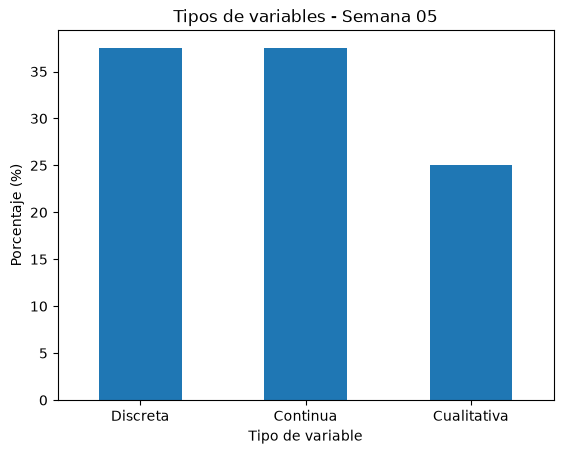

In [16]:

import matplotlib.pyplot as plt

porcentajes.plot(kind="bar")

plt.title("Tipos de variables - Semana 05")
plt.xlabel("Tipo de variable")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.show()


In [17]:

import pandas as pd

# Crear tabla de resultados
resumen = df["Respuesta"].value_counts().reset_index()
resumen.columns = ["Tipo de variable", "Cantidad"]

# Calcular porcentajes
resumen["Porcentaje (%)"] = (
    resumen["Cantidad"] / len(df) * 100
)

# Guardar en una hoja nueva del Excel existente
with pd.ExcelWriter(
    "Reto semana 05.xlsx",
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    resumen.to_excel(
        writer,
        sheet_name="Análisis Python",
        index=False
    )

print("Resultados guardados correctamente")


Resultados guardados correctamente


In [18]:

from openpyxl import load_workbook
from openpyxl.drawing.image import Image
import matplotlib.pyplot as plt

# Crear gráfica
plt.figure(figsize=(8, 5))
plt.bar(
    resumen["Tipo de variable"],
    resumen["Porcentaje (%)"]
)
plt.title("Tipos de variables - Semana 05")
plt.xlabel("Tipo de variable")
plt.ylabel("Porcentaje (%)")
plt.tight_layout()
plt.savefig("grafica_semana_05.png", dpi=150)
plt.close()

# Insertar gráfica en el Excel
wb = load_workbook("Reto semana 05.xlsx")
ws = wb["Análisis Python"]
ws.add_image(Image("grafica_semana_05.png"), "E2")
wb.save("Reto semana 05.xlsx")

print("Gráfica agregada correctamente")


Gráfica agregada correctamente
